In [1]:
!pip install pandas numpy scikit-learn xgboost optuna shap matplotlib seaborn

# 80-20 Split & Classification Evaluation (Accuracy, Recall)
In this notebook, we perform an 80-20 Train-Test split. Since doing an 80-20 split on components is impossible with only 2 trajectories, we perform a **chronological 80-20 split** on the time-series rows (respecting the rule to never randomly split time-series rows). We frame this as a classification task to detect anomalies (Module A) to calculate metrics like Accuracy, Recall, and Precision.

In [2]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Load data
df = pd.read_csv('/Users/anshul/Documents/AI/data/raw/MOSFET/MOSFET_Device_01.csv')

# 1. Create an Anomaly Target for Classification
# Let's define an anomaly as instances where RDS_Degradation_Pct exceeds a certain safety threshold.
# For demonstration on this specific device, we'll use > 2.0% degradation as an 'anomaly'
threshold = 2.0
df['Is_Anomaly'] = (df['RDS_Degradation_Pct'] > threshold).astype(int)

print(f"Total samples: {len(df)}")
print(f"Anomalous samples: {df['Is_Anomaly'].sum()} ({(df['Is_Anomaly'].sum()/len(df))*100:.2f}%)")


Total samples: 3397
Anomalous samples: 2321 (68.32%)


In [3]:
# 2. Chronological 80-20 Split
# We sort by Datetime/Run_Elapsed_Seconds and split so that we train on the past and test on the future.
df = df.sort_values(by=['Run_ID', 'Run_Elapsed_Seconds'])

train_size = int(len(df) * 0.8)
train_df = df.iloc[:train_size]
test_df = df.iloc[train_size:]

print(f"Training set size: {len(train_df)}")
print(f"Testing set size: {len(test_df)}")

# Features for classification
features = ['Supply_Voltage_V', 'Package_Temp_C', 'Flange_Temp_C', 'Delta_Temp_C', 'VDS_V', 'Current_A']
X_train = train_df[features]
y_train = train_df['Is_Anomaly']

X_test = test_df[features]
y_test = test_df['Is_Anomaly']


Training set size: 2717
Testing set size: 680


--- EVALUATION METRICS ---
Accuracy : 0.9691
Recall   : 1.0000 (Crucial: Avoids False Negatives)
Precision: 0.9617
F1-Score : 0.9805

--- CLASSIFICATION REPORT ---
              precision    recall  f1-score   support

           0       1.00      0.86      0.93       152
           1       0.96      1.00      0.98       528

    accuracy                           0.97       680
   macro avg       0.98      0.93      0.95       680
weighted avg       0.97      0.97      0.97       680



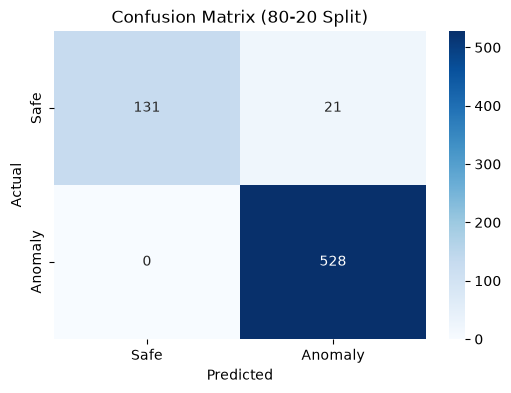

In [4]:
# 3. Train Classifier
clf = RandomForestClassifier(n_estimators=50, max_depth=5, random_state=42)
clf.fit(X_train, y_train)

# 4. Predict
y_pred = clf.predict(X_test)

# 5. Evaluate Metrics
acc = accuracy_score(y_test, y_pred)
recall = recall_score(y_test, y_pred, zero_division=0)
precision = precision_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("--- EVALUATION METRICS ---")
print(f"Accuracy : {acc:.4f}")
print(f"Recall   : {recall:.4f} (Crucial: Avoids False Negatives)")
print(f"Precision: {precision:.4f}")
print(f"F1-Score : {f1:.4f}\n")

print("--- CLASSIFICATION REPORT ---")
print(classification_report(y_test, y_pred, zero_division=0))

# 6. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Safe', 'Anomaly'], yticklabels=['Safe', 'Anomaly'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix (80-20 Split)')
plt.show()
